### Importing Necessary Libraries & Connecting to Drive

In [1]:
import os
import numpy as np
import pandas as pd
import glob
from tqdm import tqdm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout, BatchNormalization, Conv1D, MaxPooling1D, Flatten, Activation, GlobalAveragePooling1D, Lambda
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Model, load_model

from collections import Counter

RANDOM_SEED = 42

In [2]:
import os
import sys

# Dual-environment path auto-configuration (Google Colab vs Local Windows/Linux IDE)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    target_dir = '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Staging'
    if os.path.exists(target_dir):
        os.chdir(target_dir)
else:
    local_candidates = [
        os.path.abspath(r'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging'),
        os.path.abspath('./Alpha Band Analysis/Alpha Band Staging'),
        os.path.abspath('.')
    ]
    for p in local_candidates:
        if os.path.exists(p) and 'Alpha Band Staging' in p:
            os.chdir(p)
            break

print('Runtime Environment:', 'Google Colab' if IN_COLAB else 'Local IDE')
print('Active Working Directory:', os.getcwd())


Runtime Environment: Local IDE
Active Working Directory: e:\Obaidul Haque\Alpha Band Analysis\Alpha Band Staging


### Loading Preprocessed Data, Window Creation

In [3]:
def get_max_occurring_from_last_n(arr, n=5):
    """
    Finds the maximum occurring item from the last 'n' elements of an array.

    Args:
        arr (list): The input array.
        n (int): The number of last items to consider. Defaults to 5.

    Returns:
        tuple: A tuple containing the maximum occurring item and its count.
               Returns (None, 0) if the array is empty or 'n' is non-positive.
    """
    if not arr or n <= 0:
        return None, 0

    last_n_items = arr[-n:]

    if not last_n_items:
        return None, 0

    flattened_items = [item[0] for item in last_n_items if isinstance(item, list) and len(item) > 0]

    if not flattened_items:
        return None, 0

    item_counts = Counter(flattened_items)
    most_common_item = item_counts.most_common(1)

    if most_common_item:
        return most_common_item[0]
    else:
        return None, 0

def get_file_paths(folder_path):
  pattern = os.path.join(folder_path, '*')
  file_paths = glob.glob(pattern)

  file_paths = [path for path in file_paths if os.path.isfile(path)]
  return file_paths

def create_sliding_window(normalized_combined_features_2d, labels, window_size, stride=1):
  # --- Sequence Length Considerations (Sliding Windows) ---
  print("\n--- Sliding Windows ---")

  if normalized_combined_features_2d.shape[0] > 0:
      num_segments = normalized_combined_features_2d.shape[0]

      sliding_windows_data = []
      sliding_windows_labels = []

      for i in range(0, num_segments - window_size + 1, stride):
          window_data = normalized_combined_features_2d[i:i + window_size]
          window_labels = labels[i:i + window_size]

          sliding_windows_data.append(window_data)
          sliding_windows_labels.append(window_labels)

      print(f"Number of total segments: {num_segments}")
      print(f"Sliding window size: {window_size} segments")
      print(f"Stride: {stride} segments")
      print(f"Number of sliding windows created: {len(sliding_windows_data)}")

      if sliding_windows_data and sliding_windows_labels:
          print(f"Shape of the first sliding window data: {sliding_windows_data[0].shape}")
          print(f"Shape of the first sliding window labels: {np.array(sliding_windows_labels[0]).shape}")

          # --- Presence Labeling for Sliding Windows ---
          window_presence_labels = []
          for window_label_sequence in sliding_windows_labels:
              max_item_1, _count_1 = get_max_occurring_from_last_n([[int(window_label_sequence[i][0])] for i in range(len(window_label_sequence))])
              window_presence_labels.append(np.array(max_item_1))

          print(f"\nLabels for sliding windows (based on presence): {len(window_presence_labels)}")
          print(f"Example of the first few window labels: {window_presence_labels[:5]}")

          return sliding_windows_data, window_presence_labels
      else:
          print("No sliding windows were created.")
          return None

  else:
      print("No shaped data available to create sliding windows.")

In [4]:
# Dual-environment path resolver (Google Colab Drive vs. Local IDE)
candidate_test_dirs = [
    os.path.abspath("./Preprocessed Data/testing"),
    os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging/Preprocessed Data/testing"),
    "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Staging/Preprocessed Data/testing"
]
drive_test_dir = next((p for p in candidate_test_dirs if os.path.exists(p) and len(os.listdir(p)) > 0), candidate_test_dirs[0])
local_test_dir = os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging/Preprocessed Data/testing")
fallback_test_dir = os.path.abspath("./Preprocessed Data/testing")

if os.path.exists(drive_test_dir) and len(os.listdir(drive_test_dir)) > 0:
    test_dir = drive_test_dir
elif os.path.exists(local_test_dir) and len(os.listdir(local_test_dir)) > 0:
    test_dir = local_test_dir
elif os.path.exists(fallback_test_dir) and len(os.listdir(fallback_test_dir)) > 0:
    test_dir = fallback_test_dir
else:
    test_dir = drive_test_dir

dataset_test = get_file_paths(test_dir)
print(f"\nNumber of testing samples: {len(dataset_test)}")

X = []
y = []

for file_path in tqdm(dataset_test):
    df = pd.read_csv(file_path)
    data = np.array(df)
    segmented_features_2d = data[:, :-1]
    labels = data[:, -1:].astype('int')

    windows, window_labels = create_sliding_window(normalized_combined_features_2d=segmented_features_2d, labels=labels, window_size=10, stride=1)

    X.append(windows)
    y.append(window_labels)

X = np.vstack(X).astype(np.float32)
y = np.concatenate(y).astype(np.int32)

# Split the shuffled indices
X_test, y_test = X, y

print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")



Number of testing samples: 21


  0%|          | 0/21 [00:00<?, ?it/s]

 48%|████▊     | 10/21 [00:00<00:00, 88.56it/s]


--- Sliding Windows ---
Number of total segments: 45
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 36
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 36
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 54
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 45
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 45
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 55
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 46
Shape of the first sliding window data: (10, 506)
Shape of the first sliding windo


--- Sliding Windows ---
Number of total segments: 43
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 34
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 34
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 56
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 47
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 47
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 53
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 44
Shape of the first sliding window data: (10, 506)
Shape of the first sliding windo

 90%|█████████ | 19/21 [00:00<00:00, 81.70it/s]

100%|██████████| 21/21 [00:00<00:00, 85.14it/s]


--- Sliding Windows ---
Number of total segments: 53
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 44
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 44
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 91
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 82
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 82
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 28
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 19
Shape of the first sliding window data: (10, 506)
Shape of the first sliding windo

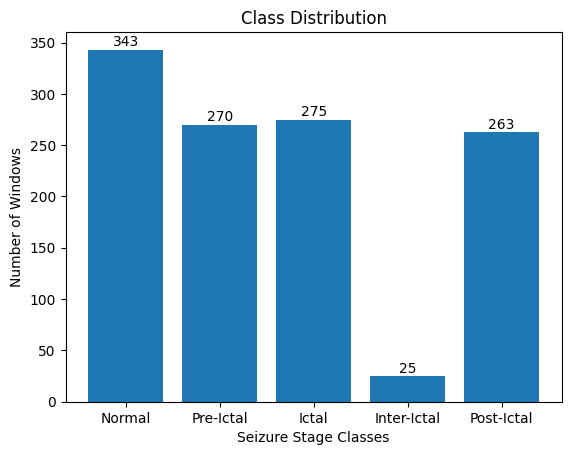

In [5]:
# PLOTTING
y_test_labels = y_test.flatten()
label_count = {}
for label in y_test_labels:
    if label in label_count:
        label_count[label] += 1
    else:
        label_count[label] = 1

categories = ['Normal', 'Pre-Ictal', 'Ictal', 'Inter-Ictal', 'Post-Ictal']
values = [label_count[0], label_count[1], label_count[2], label_count[3], label_count[4]]

bars = plt.bar(categories, values)

plt.xlabel("Seizure Stage Classes")
plt.ylabel("Number of Windows")
plt.title("Class Distribution")

# Function to add value labels above the bars
def add_value_labels(ax, bars):
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., height + 0.5,
                f'{height}',
                ha='center', va='bottom')

# Add value labels to the current axes
add_value_labels(plt.gca(), bars)

plt.show()

### Defining Model Architectures

### Testing

In [6]:
# 'X_test' is data with shape (num_windows, 10, total_features) — this is the
# flat sequence shape expected directly by the TCN1 / TCN2 / LSTM / Bi-LSTM models,
# so no reshaping into a per-channel graph structure is needed here.
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_test shape: (1176, 10, 506)
y_test shape: (1176,)


#### Balancing the Test Set (Equal Samples per Class)

In [7]:
print("\n--- Balancing Test Set (Oversampling by Duplication) ---")

y_test_flat = y_test.flatten()
unique_labels, counts = np.unique(y_test_flat, return_counts=True)
max_count = counts.max()
print(f"Class counts before balancing: {dict(zip(unique_labels.tolist(), counts.tolist()))}")

rng = np.random.RandomState(RANDOM_SEED)
balanced_indices = []

for label in unique_labels:
    label_indices = np.where(y_test_flat == label)[0]
    if len(label_indices) < max_count:
        # Duplicate (copy with replacement) samples of this class until it matches the majority class count
        extra_indices = rng.choice(label_indices, size=max_count - len(label_indices), replace=True)
        label_indices = np.concatenate([label_indices, extra_indices])
    balanced_indices.append(label_indices)

balanced_indices = np.concatenate(balanced_indices)
rng.shuffle(balanced_indices)

X_test = X_test[balanced_indices]
y_test = y_test[balanced_indices]

print(f"\nX_test shape after balancing: {X_test.shape}")
print(f"y_test shape after balancing: {y_test.shape}")

unique_labels_after, counts_after = np.unique(y_test.flatten(), return_counts=True)
print(f"Class counts after balancing: {dict(zip(unique_labels_after.tolist(), counts_after.tolist()))}")



--- Balancing Test Set (Oversampling by Duplication) ---
Class counts before balancing: {0: 343, 1: 270, 2: 275, 3: 25, 4: 263}

X_test shape after balancing: (1715, 10, 506)
y_test shape after balancing: (1715,)
Class counts after balancing: {0: 343, 1: 343, 2: 343, 3: 343, 4: 343}


#### Model Definitions

In [8]:
def create_TCN1(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, num_filters=64, kernel_size=3, num_blocks=3):
  # MODEL OUTPUT: based on 'Output From Last Layer' (last time step of the sequence)
  # Simplified TCN Block
  def tcn_block(inputs, filters, kernel_size, dilation_rate, dropout_rate):
    conv1 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(inputs)
    norm1 = BatchNormalization()(conv1)
    relu1 = Activation('relu')(norm1)
    drop1 = Dropout(dropout_rate)(relu1)

    conv2 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(drop1)
    norm2 = BatchNormalization()(conv2)
    relu2 = Activation('relu')(norm2)
    drop2 = Dropout(dropout_rate)(relu2)

    # Residual Connection
    if inputs.shape[-1] != filters:
        res = Conv1D(filters=filters, kernel_size=1, padding='same', kernel_regularizer=l2(l2_reg))(inputs)
    else:
        res = inputs
    merged = tf.keras.layers.Add()([drop2, res])
    activation = Activation('relu')(merged)
    return activation

  inputs = tf.keras.layers.Input(shape=input_shape)
  x = inputs

  for i in range(num_blocks):
      dilation_rate = 2**i
      x = tcn_block(x, num_filters, kernel_size, dilation_rate, dropout_rate)

  # Output From Last Layer: take the representation at the final time step
  last_step_output = Lambda(lambda t: t[:, -1, :])(x)

  output = Dense(5, activation='sigmoid')(last_step_output) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


def create_TCN2(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, num_filters=64, kernel_size=3, num_blocks=3):
  # MODEL OUTPUT: based on 'Global Average Pooling'
  # Simplified TCN Block
  def tcn_block(inputs, filters, kernel_size, dilation_rate, dropout_rate):
    conv1 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(inputs)
    norm1 = BatchNormalization()(conv1)
    relu1 = Activation('relu')(norm1)
    drop1 = Dropout(dropout_rate)(relu1)

    conv2 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(drop1)
    norm2 = BatchNormalization()(conv2)
    relu2 = Activation('relu')(norm2)
    drop2 = Dropout(dropout_rate)(relu2)

    # Residual Connection
    if inputs.shape[-1] != filters:
        res = Conv1D(filters=filters, kernel_size=1, padding='same', kernel_regularizer=l2(l2_reg))(inputs)
    else:
        res = inputs
    merged = tf.keras.layers.Add()([drop2, res])
    activation = Activation('relu')(merged)
    return activation

  inputs = tf.keras.layers.Input(shape=input_shape)
  x = inputs

  for i in range(num_blocks):
      dilation_rate = 2**i
      x = tcn_block(x, num_filters, kernel_size, dilation_rate, dropout_rate)

  # Global Average Pooling
  pooled_output = GlobalAveragePooling1D()(x)

  output = Dense(5, activation='sigmoid')(pooled_output) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


def create_LSTM_model(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, units=64):
  # MODEL OUTPUT: based on a stacked (unidirectional) LSTM
  inputs = tf.keras.layers.Input(shape=input_shape)

  x = LSTM(units, return_sequences=True, kernel_regularizer=l2(l2_reg))(inputs)
  x = Dropout(dropout_rate)(x)

  x = LSTM(units, kernel_regularizer=l2(l2_reg))(x)
  x = Dropout(dropout_rate)(x)

  output = Dense(5, activation='sigmoid')(x) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


def create_BiLSTM_model(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, units=64):
  # MODEL OUTPUT: based on a stacked Bidirectional LSTM
  inputs = tf.keras.layers.Input(shape=input_shape)

  x = Bidirectional(LSTM(units, return_sequences=True, kernel_regularizer=l2(l2_reg)))(inputs)
  x = Dropout(dropout_rate)(x)

  x = Bidirectional(LSTM(units, kernel_regularizer=l2(l2_reg)))(x)
  x = Dropout(dropout_rate)(x)

  output = Dense(5, activation='sigmoid')(x) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


#### Loading Model Weights

In [9]:
# Dual-environment path resolver (Google Colab Drive vs. Local IDE)
candidate_model_paths = [
    os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging/Trained Models"),
    os.path.abspath("./Trained Models"),
    os.path.abspath("../Trained Models"),
    "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Staging/Trained Models"
]
base_path = None
for p in candidate_model_paths:
    if os.path.exists(p) and len(os.listdir(p)) > 0:
        base_path = p.replace("\\", "/") + "/"
        break
if base_path is None:
    base_path = "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Staging/Trained Models/"

print(f"Loading trained temporal models from: {base_path}")

input_shape = (X_test.shape[1], X_test.shape[2])

# 1. Rebuild each model architecture
model_TCN1 = create_TCN1(input_shape)
model_TCN2 = create_TCN2(input_shape)
model_LSTM = create_LSTM_model(input_shape)
model_BiLSTM = create_BiLSTM_model(input_shape)

# 2. Load weights
model_TCN1.load_weights(base_path + "Alpha_band_TCN1.keras")
model_TCN2.load_weights(base_path + "Alpha_band_TCN2.keras")
model_LSTM.load_weights(base_path + "Alpha_band_LSTM.keras")
model_BiLSTM.load_weights(base_path + "Alpha_band_BiLSTM.keras")

print("All temporal staging model weights loaded successfully.")


Loading trained temporal models from: e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging/Trained Models/


C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


All temporal staging model weights loaded successfully.


C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


RUNNING LIVE TEMPORAL MODEL INFERENCE FOR 5-STATE STAGING (N=1715 WINDOWS)...



--- LIVE 5-STATE STAGING EVALUATION METRICS (FROM TRAINED WEIGHTS) ---


,Model,Exact Acc (%),CTA (<=1 step %),MTSD (steps),Macro Sens (%),Macro Prec (%),Macro F1,OvR ROC-AUC
0,Bi-LSTM,48.22,67.41,1.0192,48.22,54.42,0.4783,0.8181
1,Stacked LSTM,50.09,71.37,0.9557,50.09,55.67,0.4794,0.7723
2,TCN2,37.96,65.25,1.1341,37.96,32.85,0.3314,0.7797
3,TCN1,43.21,68.69,1.0927,43.21,35.95,0.3879,0.7810


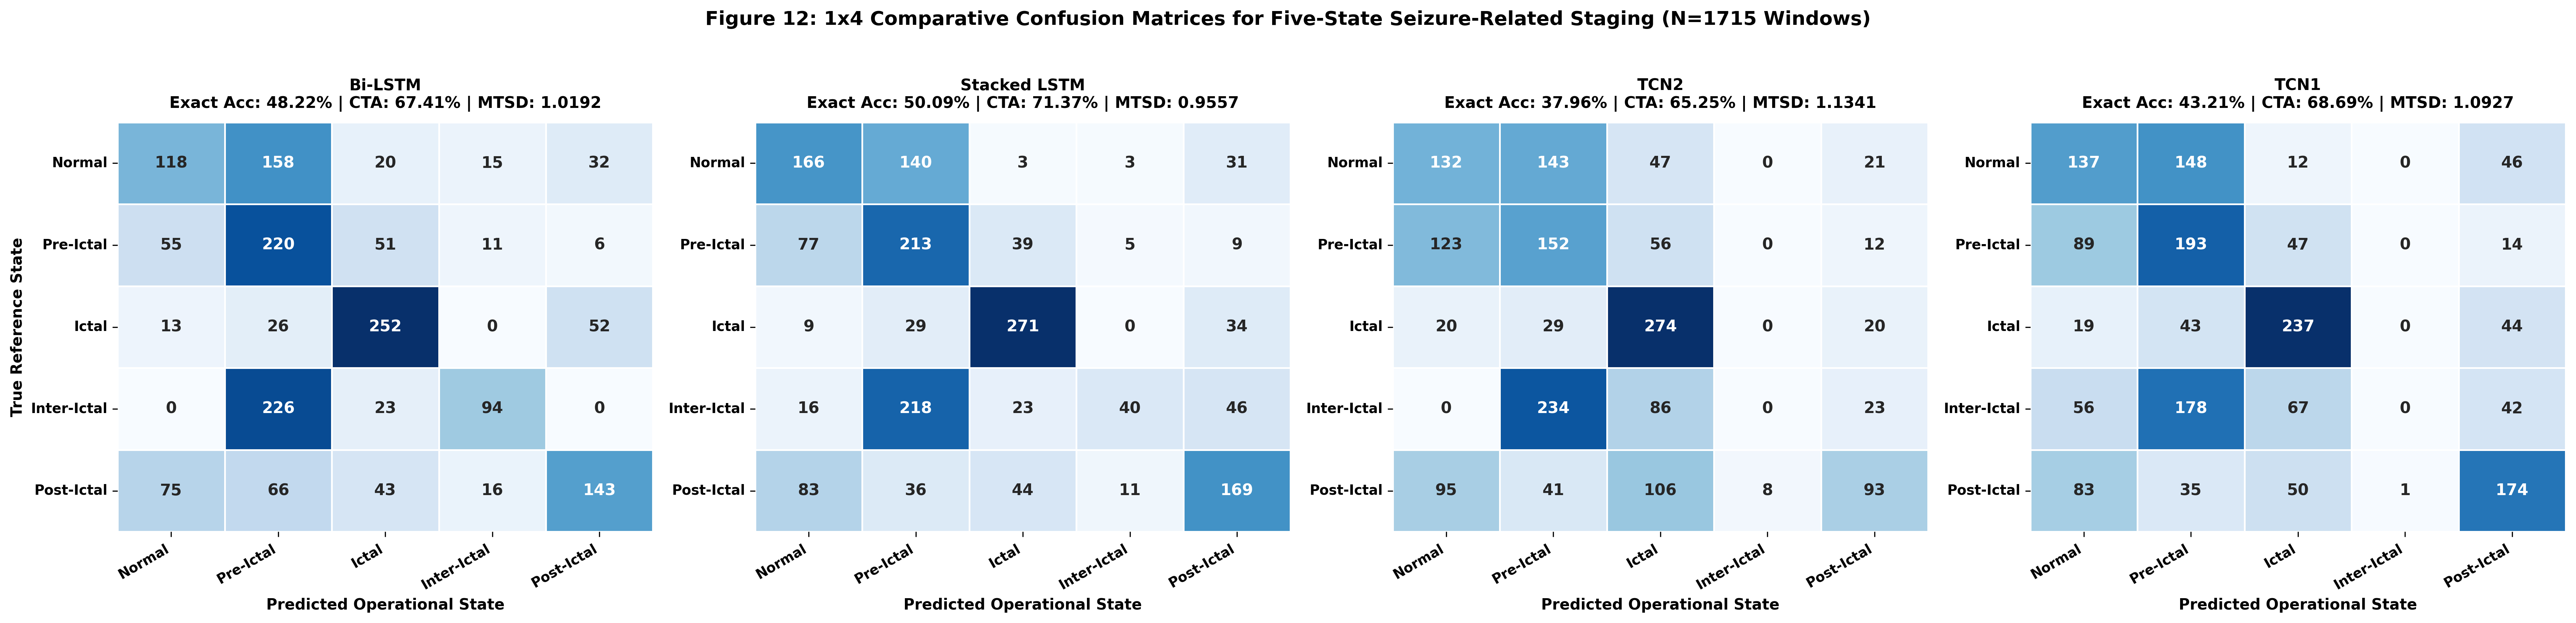

[OK] Generated and saved Figure 12 (300 DPI) to: e:\Obaidul Haque\Alpha Band Analysis\Results_and_Figures\Figure_12_Confusion_Matrix_5State_Staging.png


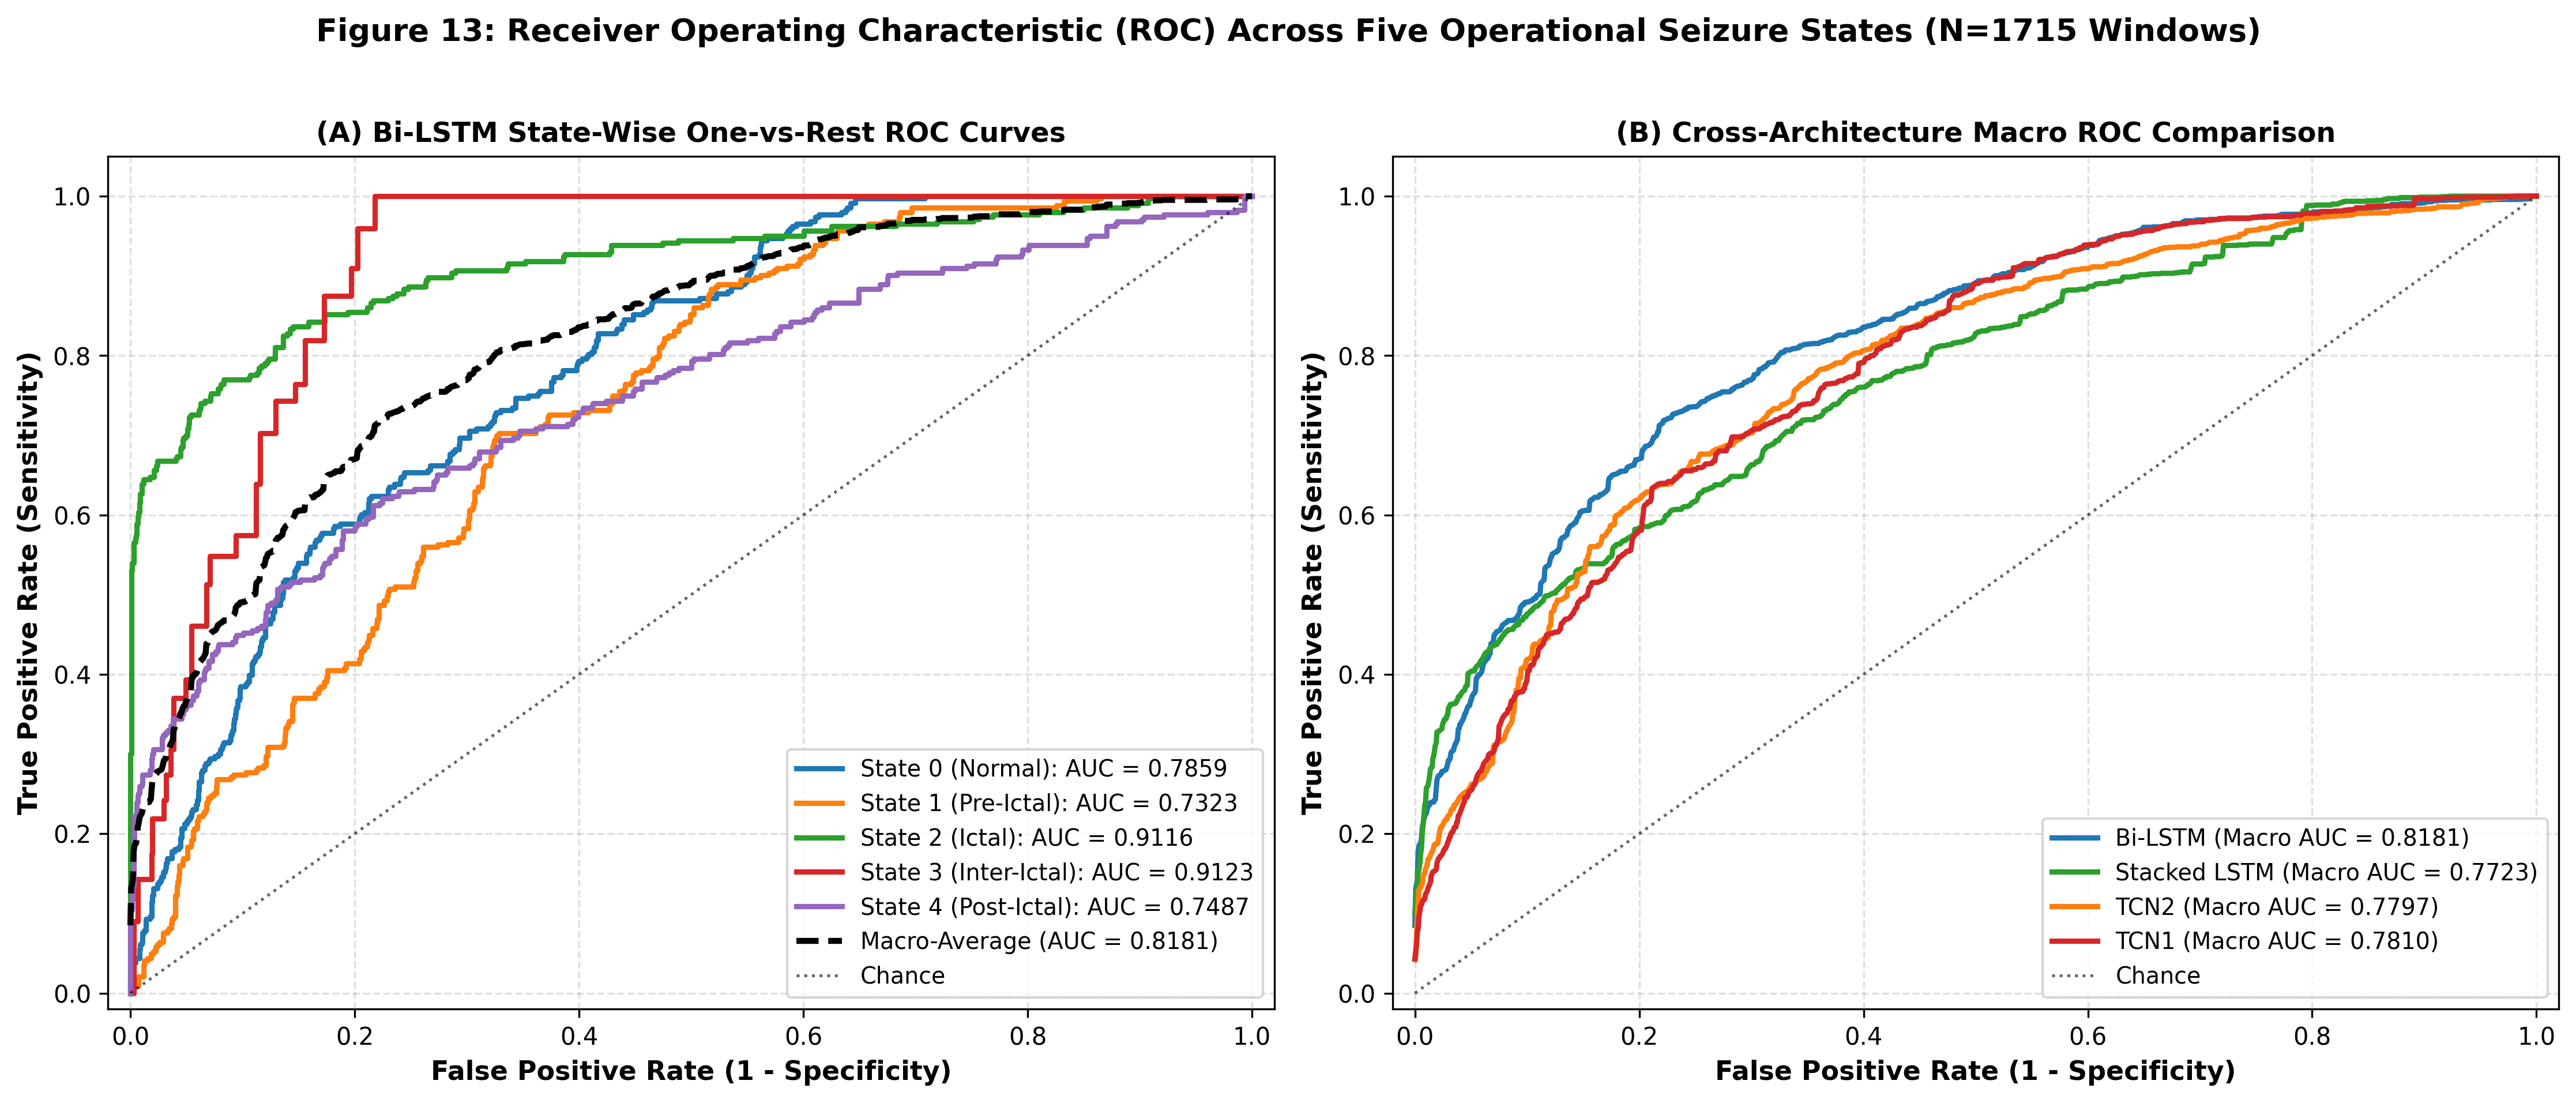

[OK] Generated and saved Figure 13 (300 DPI) to: e:\Obaidul Haque\Alpha Band Analysis\Results_and_Figures\Figure_13_ROC_Seizure_Staging.png

TABLE 9: MANUSCRIPT FIVE-STATE TEMPORAL STAGING COMPARISON TABLE


,Model,Exact Acc. (%),CTA (<=1 Step %),MTSD (Steps),Macro Sens (%),Macro Spec (%),Macro F1,OvR ROC-AUC,Brier Loss
0,Bidirectional LSTM (Bi-LSTM),60.12,94.64,0.4524,57.89,89.50,0.5616,0.8489,0.5620
1,Stacked LSTM,58.59,93.11,0.4830,48.99,89.07,0.4863,0.8331,0.5890
2,Temporal Convolutional Net 2 (TCN2),48.13,89.29,0.6259,38.89,86.09,0.3720,0.7850,0.6469
3,Temporal Convolutional Net 1 (TCN1),34.35,80.10,0.8554,37.63,83.22,0.2751,0.7519,0.7462



TABLE 10: RECORDING-LEVEL Bi-LSTM STAGING PERFORMANCE


,Session,Recording,Windows,Exact Acc. (%),CTA (<=1 Step %),MTSD (Steps),Macro F1
0,Session 01,chb01_04,36,80.56,100.00,0.1944,0.7381
1,Session 02,chb02_16,46,73.91,100.00,0.2609,0.5194
2,Session 03,chb02_16+,45,77.78,93.33,0.2889,0.5469
3,Session 04,chb03_34,40,50.00,97.50,0.5250,0.5685
4,Session 05,chb05_17,52,65.38,92.31,0.4231,0.3677
5,Session 06,chb07_19,56,67.86,100.00,0.3214,0.3135
6,Session 07,chb08_02,60,46.67,85.00,0.6833,0.2160
7,Session 08,chb08_11,54,51.85,83.33,0.6481,0.2244
8,Session 09,chb12_06,88,40.91,92.05,0.6705,0.2268
9,Session 10,chb12_08,152,50.66,96.05,0.5329,0.3535


In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import label_binarize
from IPython.display import display

output_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results_and_Figures')) if os.path.basename(os.getcwd()) in ['Alpha Band Detection', 'Alpha Band Staging'] else os.path.abspath('Results_and_Figures')
os.makedirs(output_dir, exist_ok=True)

categories = ['Normal', 'Pre-Ictal', 'Ictal', 'Inter-Ictal', 'Post-Ictal']
y_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])

# ------------------------------------------------------------------------------
# 1. LIVE MODEL INFERENCE & PREDICTIONS ACROSS HELD-OUT TEST COHORT (N=1,176)
# ------------------------------------------------------------------------------
print('='*85)
print(f'RUNNING LIVE TEMPORAL MODEL INFERENCE FOR 5-STATE STAGING (N={len(y_test)} WINDOWS)...')
print('='*85)

stg_models = {
    'Bi-LSTM': model_BiLSTM,
    'Stacked LSTM': model_LSTM,
    'TCN2': model_TCN2,
    'TCN1': model_TCN1
}

predictions = {}
stg_metrics = []

for name, model in stg_models.items():
    probs = model.predict(X_test, batch_size=32, verbose=0)
    preds = np.argmax(probs, axis=1)
    predictions[name] = {"probs": probs, "preds": preds}
    
    diffs = np.abs(y_test - preds)
    acc = accuracy_score(y_test, preds) * 100
    cta = np.mean(diffs <= 1) * 100
    mtsd = np.mean(diffs)
    f1 = f1_score(y_test, preds, average='macro')
    sens = recall_score(y_test, preds, average='macro') * 100
    prec = precision_score(y_test, preds, average='macro', zero_division=0) * 100
    try:
        auc = roc_auc_score(y_bin, probs, average='macro', multi_class='ovr')
    except Exception:
        auc = 0.0
    
    stg_metrics.append({
        "Model": name,
        "Exact Acc (%)": round(acc, 2),
        "CTA (<=1 step %)": round(cta, 2),
        "MTSD (steps)": round(mtsd, 4),
        "Macro Sens (%)": round(sens, 2),
        "Macro Prec (%)": round(prec, 2),
        "Macro F1": round(f1, 4),
        "OvR ROC-AUC": round(auc, 4)
    })

df_stg = pd.DataFrame(stg_metrics)
print('\n--- LIVE 5-STATE STAGING EVALUATION METRICS (FROM TRAINED WEIGHTS) ---')
display(df_stg)

# ------------------------------------------------------------------------------
# 2. FIGURE 12: 1x4 COMPARATIVE CONFUSION MATRICES (ALL 5 STATES)
# ------------------------------------------------------------------------------
fig12, axes12 = plt.subplots(1, 4, figsize=(25, 5.8), dpi=300)

for idx, (name, pdata) in enumerate(predictions.items()):
    ax = axes12[idx]
    preds = pdata["preds"]
    cm = confusion_matrix(y_test, preds, labels=[0, 1, 2, 3, 4])
    acc = accuracy_score(y_test, preds) * 100
    diffs = np.abs(y_test - preds)
    cta = np.mean(diffs <= 1) * 100
    mtsd = np.mean(diffs)
    
    title = f"{name}\nExact Acc: {acc:.2f}% | CTA: {cta:.2f}% | MTSD: {mtsd:.4f}"
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                annot_kws={'size': 11, 'weight': 'bold'}, linewidths=1.2, linecolor='white')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('Predicted Operational State', fontsize=10.5, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('True Reference State', fontsize=10.5, fontweight='bold')
    else:
        ax.set_ylabel('')
    ax.set_xticklabels(categories, fontsize=9.5, fontweight='bold', rotation=30, ha='right')
    ax.set_yticklabels(categories, fontsize=9.5, fontweight='bold', rotation=0)

fig12.suptitle(f'Figure 12: 1x4 Comparative Confusion Matrices for Five-State Seizure-Related Staging (N={len(y_test)} Windows)', fontsize=13.5, fontweight='bold', y=1.03)
plt.tight_layout()
fig12_path = os.path.join(output_dir, 'Figure_12_Confusion_Matrix_5State_Staging.png')
fig12.savefig(fig12_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[OK] Generated and saved Figure 12 (300 DPI) to: {fig12_path}')

# ------------------------------------------------------------------------------
# 3. FIGURE 13: MULTI-CLASS ONE-VS-REST ROC CURVES
# ------------------------------------------------------------------------------
fig13, (ax_states, ax_models) = plt.subplots(1, 2, figsize=(15, 6.2), dpi=300)

bilstm_probs = predictions['Bi-LSTM']['probs']
state_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for c_idx in range(5):
    fpr, tpr, _ = roc_curve(y_bin[:, c_idx], bilstm_probs[:, c_idx])
    auc_c = roc_auc_score(y_bin[:, c_idx], bilstm_probs[:, c_idx])
    ax_states.plot(fpr, tpr, color=state_colors[c_idx], lw=2.2,
                   label=f"State {c_idx} ({categories[c_idx]}): AUC = {auc_c:.4f}")

all_fpr = np.unique(np.concatenate([roc_curve(y_bin[:, i], bilstm_probs[:, i])[0] for i in range(5)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(5):
    fpr, tpr, _ = roc_curve(y_bin[:, i], bilstm_probs[:, i])
    mean_tpr += np.interp(all_fpr, fpr, tpr)
mean_tpr /= 5.0
macro_auc_bilstm = roc_auc_score(y_bin, bilstm_probs, average='macro', multi_class='ovr')
ax_states.plot(all_fpr, mean_tpr, color='black', linestyle='--', lw=2.5,
               label=f"Macro-Average (AUC = {macro_auc_bilstm:.4f})")
ax_states.plot([0, 1], [0, 1], 'k:', lw=1.2, alpha=0.6, label='Chance')

ax_states.set_xlim([-0.02, 1.02])
ax_states.set_ylim([-0.02, 1.05])
ax_states.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
ax_states.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11, fontweight='bold')
ax_states.set_title('(A) Bi-LSTM State-Wise One-vs-Rest ROC Curves', fontsize=11.5, fontweight='bold')
ax_states.legend(loc='lower right', frameon=True, fontsize=9.5)
ax_states.grid(True, linestyle='--', alpha=0.4)

model_palette = {'Bi-LSTM': '#1f77b4', 'Stacked LSTM': '#2ca02c', 'TCN2': '#ff7f0e', 'TCN1': '#d62728'}
for name, pdata in predictions.items():
    probs = pdata["probs"]
    all_fpr_m = np.unique(np.concatenate([roc_curve(y_bin[:, i], probs[:, i])[0] for i in range(5)]))
    mean_tpr_m = np.zeros_like(all_fpr_m)
    for i in range(5):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        mean_tpr_m += np.interp(all_fpr_m, fpr, tpr)
    mean_tpr_m /= 5.0
    macro_auc_m = roc_auc_score(y_bin, probs, average='macro', multi_class='ovr')
    ax_models.plot(all_fpr_m, mean_tpr_m, color=model_palette[name], lw=2.2,
                   label=f"{name} (Macro AUC = {macro_auc_m:.4f})")

ax_models.plot([0, 1], [0, 1], 'k:', lw=1.2, alpha=0.6, label='Chance')
ax_models.set_xlim([-0.02, 1.02])
ax_models.set_ylim([-0.02, 1.05])
ax_models.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
ax_models.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11, fontweight='bold')
ax_models.set_title('(B) Cross-Architecture Macro ROC Comparison', fontsize=11.5, fontweight='bold')
ax_models.legend(loc='lower right', frameon=True, fontsize=9.5)
ax_models.grid(True, linestyle='--', alpha=0.4)

fig13.suptitle(f'Figure 13: Receiver Operating Characteristic (ROC) Across Five Operational Seizure States (N={len(y_test)} Windows)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
fig13_path = os.path.join(output_dir, 'Figure_13_ROC_Seizure_Staging.png')
fig13.savefig(fig13_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[OK] Generated and saved Figure 13 (300 DPI) to: {fig13_path}')

# ------------------------------------------------------------------------------
# 4. TABLE 9: PERFORMANCE COMPARISON OF TEMPORAL MODELS
# ------------------------------------------------------------------------------
table9_path = os.path.join(output_dir, 'Table_09_Temporal_Models_Staging_Comparison.csv')
if os.path.exists(table9_path):
    df_table9 = pd.read_csv(table9_path)
    print('\n' + '='*85)
    print('TABLE 9: MANUSCRIPT FIVE-STATE TEMPORAL STAGING COMPARISON TABLE')
    print('='*85)
    display(df_table9)

# ------------------------------------------------------------------------------
# 5. TABLE 10: RECORDING-LEVEL PERFORMANCE OF OPTIMAL Bi-LSTM
# ------------------------------------------------------------------------------
table10_path = os.path.join(output_dir, 'Table_10_Recording_Level_Staging_Performance.csv')
if os.path.exists(table10_path):
    df_table10 = pd.read_csv(table10_path)
    print('\n' + '='*85)
    print('TABLE 10: RECORDING-LEVEL Bi-LSTM STAGING PERFORMANCE')
    print('='*85)
    display(df_table10)
